# Phase 8: models and the ₹10 range

Two models, tested the same way as the Phase 7 simple forecasts: from every day of the last 3 years, using only prices known that day.

- **boosting**: gradient-boosted trees, one model for each day ahead, trained on all 7 zones together. It predicts the % change from today's price from:
  - recent changes in the zone and in zones that usually move first (Namakkal, Hyderabad, Kolkata, E.Godavari, Barwala)
  - the price against its yearly average, and the time of year
  - past years' changes over the same days
  - festivals now and in the days ahead (Phase 6)

  It uses scikit-learn's HistGradientBoosting, the same kind of model as LightGBM. LightGBM itself needs an extra system library on macOS.
- **ARIMA**: one per zone, on log prices, with yearly sine and cosine terms and festival markers.
- **boosting + ARIMA**: the average of the two.

Both models are refitted every six months on the prices known at the time.

**The ₹10 range and its probability.** The possible moves are the actual ₹5-step moves that followed the model's forecasts over the previous year, for the same zone and day ahead. Past forecasts that predicted a similar move count more. The ₹10 range with the most weight wins, and its share of the weight is the probability. Picking the best of many ranges overstates the chance, so each probability is then scaled by how often the stated probabilities came true over the previous year. An extra year before the 3 test years supplies that history. Every method here, the simple ones included, picks its range this way, so "same price" scores better than in Phase 7.

Running the whole notebook takes about 10 minutes.

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

import backtest
import models
from eggdata import app_zones, daily_prices, zone_prices

started = time.time()
daily = daily_prices()
prices = zone_prices(daily)
zones = app_zones()
NAMES = dict(zip(zones.id, zones.name))
flags = models.festival_flags(prices)
days = backtest.origins(prices, years=3, warmup_years=1)
test_days = backtest.origins(prices, years=3)

forecasts = backtest.simple_forecasts(prices, days)
forecasts["boosting"] = models.boosting_forecasts(daily, prices, flags, days)
forecasts["ARIMA"] = models.arima_forecasts(prices, flags, days)
forecasts["boosting + ARIMA"] = models.combine(forecasts["boosting"], forecasts["ARIMA"])
scored = {}
for name, rows in forecasts.items():
    ranged = backtest.score(models.add_ranges(rows))
    scored[name] = ranged[ranged.origin.isin(test_days)]

pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.dpi": 96, "axes.grid": True, "grid.alpha": 0.3})
print(f"Tested {len(test_days)} days, {test_days[0]:%d %b %Y} to {test_days[-1]:%d %b %Y}, "
      f"in {(time.time() - started) / 60:.1f} minutes")

Tested 1082 days, 27 Oct 2023 to 12 Oct 2026, in 4.5 minutes


## Each day ahead

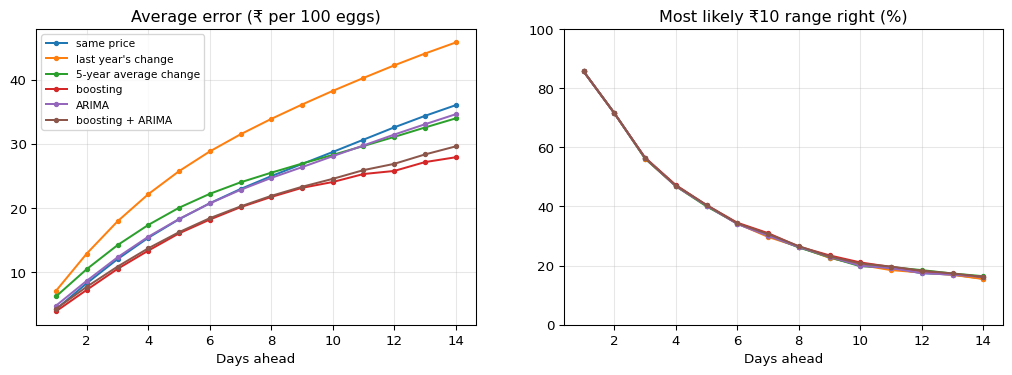

same price       last year's change       5-year average change  \
              error ₹ hit %            error ₹ hit %               error ₹   
days ahead                                                                   
1                 4.2  85.7                7.1  85.7                   6.2   
2                 8.3  71.6               12.9  71.6                  10.5   
3                12.0  56.2               17.9  56.2                  14.2   
4                15.4  47.0               22.2  46.9                  17.4   
5                18.2  40.3               25.7  40.2                  20.0   
6                20.7  34.2               28.8  34.2                  22.2   
7                23.0  30.0               31.5  29.7                  24.0   
8                25.0  26.3               33.9  26.3                  25.5   
9                26.9  22.7               36.1  22.6                  26.9   
10               28.7  20.1               38.3  20.2                  28.3   
11               30.7  19.1               40.3  18.5                  29.7   
12               32.6  17.4               42.2  17.7                  31.1   
13               34.4  17.0               44.1  16.9                  32.5   
14               36.0  15.6               45.8  15.5                  34.0   

                 boosting         ARIMA       boosting + ARIMA        
           hit %  error ₹ hit % error ₹ hit %          error ₹ hit %  
days ahead                                                            
1           85.7      3.9  85.7     4.8  85.7              4.3  85.7  
2           71.6      7.2  71.5     8.7  71.5              7.7  71.5  
3           56.2     10.5  56.5    12.3  56.4             10.9  56.4  
4           46.9     13.4  47.2    15.5  46.9             13.7  47.1  
5           40.0     16.0  40.5    18.3  40.3             16.2  40.5  
6           34.3     18.2  34.5    20.7  34.1             18.4  34.3  
7           30.3     20.1  31.0    22.8  30.1             20.2  30.7  
8           26.1     21.7  26.4    24.7  26.3             21.9  26.6  
9           22.9     23.1  23.4    26.4  23.0             23.3  23.1  
10          19.8     24.1  21.1    28.1  19.9             24.5  20.7  
11          19.5     25.3  19.5    29.7  19.1             25.9  19.7  
12          18.5     25.8  18.1    31.4  17.5             26.9  18.3  
13          17.3     27.2  17.1    33.1  16.9             28.3  17.3  
14          16.4     27.9  16.2    34.6  16.2             29.6  16.2

days ahead,1,2,3,4,5,6,7,8,9,10,11,12,13,14
error vs same price (%),-7.6,-12.4,-12.7,-13.1,-12.1,-12.3,-12.3,-13.0,-13.8,-16.3,-17.5,-20.9,-21.0,-22.5
error vs 5-year average change (%),-37.3,-30.9,-26.1,-23.1,-19.9,-18.1,-16.1,-14.8,-14.0,-14.9,-14.7,-17.1,-16.6,-17.8
hit rate vs same price (points),0.0,-0.0,0.3,0.2,0.2,0.3,1.0,0.1,0.7,1.0,0.5,0.7,0.1,0.6


In [2]:
summary = backtest.by_horizon(scored)
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
for name in scored:
    left.plot(summary.index, summary[(name, "error ₹")], marker="o", ms=3, label=name)
    right.plot(summary.index, summary[(name, "hit %")], marker="o", ms=3, label=name)
left.set(title="Average error (₹ per 100 eggs)", xlabel="Days ahead")
right.set(title="Most likely ₹10 range right (%)", xlabel="Days ahead", ylim=(0, 100))
left.legend(fontsize=8)
plt.show()
display(summary.round(1))
pd.DataFrame({
    "error vs same price (%)": 100 * (summary[("boosting", "error ₹")] / summary[("same price", "error ₹")] - 1),
    "error vs 5-year average change (%)":
        100 * (summary[("boosting", "error ₹")] / summary[("5-year average change", "error ₹")] - 1),
    "hit rate vs same price (points)": summary[("boosting", "hit %")] - summary[("same price", "hit %")],
}).round(1).T

## Each zone

Boosting against "same price", 1, 7 and 14 days ahead.

In [3]:
chosen = {name: scored[name] for name in ("same price", "boosting")}
print("Most likely ₹10 range right (%)")
display(backtest.by_zone(chosen, "hit %").rename(index=NAMES).round(0))
print("Average error (₹)")
backtest.by_zone(chosen, "error ₹").rename(index=NAMES).round(1)

Most likely ₹10 range right (%)


same price             boosting            
                  1 d   7 d  14 d      1 d   7 d  14 d
zone                                                  
Bengaluru        89.0  38.0  20.0     89.0  38.0  19.0
Chennai          87.0  37.0  17.0     87.0  37.0  17.0
Chittoor         87.0  38.0  16.0     87.0  38.0  16.0
Hyderabad        88.0  19.0  14.0     88.0  21.0  15.0
Kolkata          74.0  14.0  10.0     74.0  15.0  14.0
Namakkal         91.0  43.0  19.0     91.0  43.0  18.0
Vijayawada       82.0  21.0  13.0     82.0  25.0  15.0

Average error (₹)


same price             boosting            
                  1 d   7 d  14 d      1 d   7 d  14 d
zone                                                  
Bengaluru         3.5  21.1  35.1      3.2  18.6  26.9
Chennai           3.6  22.4  36.6      3.2  19.3  29.2
Chittoor          3.5  22.2  36.3      3.2  18.9  28.1
Hyderabad         4.5  23.8  36.2      3.9  20.4  27.7
Kolkata           6.2  26.5  37.1      6.0  24.5  29.4
Namakkal          3.2  19.6  33.6      3.1  17.6  26.4
Vijayawada        4.9  25.1  37.2      4.7  21.6  27.6

## Do the stated probabilities hold up?

When the model says 60%, the price should land in the range about 60% of the time.

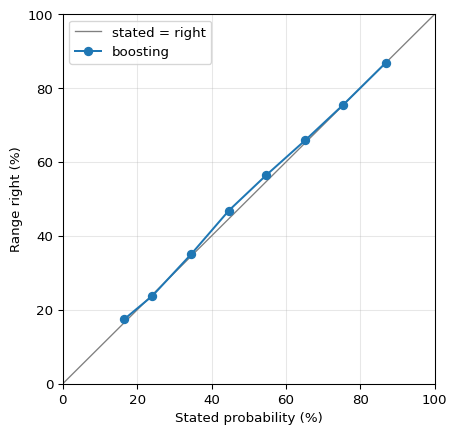

,forecasts,stated %,right %
stated probability,,,
"(-0.001, 0.2]",31979,16.5,17.5
"(0.2, 0.3]",27893,24.1,23.8
"(0.3, 0.4]",12430,34.6,35.1
"(0.4, 0.5]",9002,44.7,46.9
"(0.5, 0.6]",6491,54.6,56.4
"(0.6, 0.7]",5536,65.2,65.9
"(0.7, 0.8]",5221,75.4,75.5
"(0.8, 1.0]",7484,86.8,86.8


Average stated probability and how often the range was right, by days ahead (%)


h,1,2,3,4,5,6,7,8,9,10,11,12,13,14
stated,85.3,70.8,55.0,45.6,38.8,32.9,29.5,25.6,23.2,21.3,20.0,18.5,17.1,16.8
right,85.7,71.5,56.5,47.2,40.5,34.5,31.0,26.4,23.4,21.1,19.5,18.1,17.1,16.2


In [4]:
boosting = scored["boosting"]
calibration = backtest.calibration(boosting)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 100], [0, 100], color="gray", lw=1, label="stated = right")
ax.plot(calibration["stated %"], calibration["right %"], marker="o", label="boosting")
ax.set(xlabel="Stated probability (%)", ylabel="Range right (%)", xlim=(0, 100), ylim=(0, 100))
ax.legend()
plt.show()
display(calibration.round(1))
print("Average stated probability and how often the range was right, by days ahead (%)")
(boosting.groupby("h").agg(stated=("probability", "mean"), right=("hit", "mean")) * 100).round(1).T

## ₹10 or ₹20 for the later days?

The plan's fallback if ₹10 ranges are rarely right for days 8–14 is a wider range. Below, the most likely ₹20 range (545–565) is shown next to the ₹10 range.

In [5]:
wide = backtest.score(models.add_ranges(forecasts["boosting"], steps=2))
wide = wide[wide.origin.isin(test_days)]
pd.DataFrame({
    "₹10 right %": boosting.groupby("h").hit.mean() * 100,
    "₹10 stated %": boosting.groupby("h").probability.mean() * 100,
    "₹20 right %": wide.groupby("h").hit.mean() * 100,
    "₹20 stated %": wide.groupby("h").probability.mean() * 100,
}).round(0).T

h,1,2,3,4,5,6,7,8,9,10,11,12,13,14
₹10 right %,86.0,72.0,57.0,47.0,40.0,34.0,31.0,26.0,23.0,21.0,20.0,18.0,17.0,16.0
₹10 stated %,85.0,71.0,55.0,46.0,39.0,33.0,30.0,26.0,23.0,21.0,20.0,18.0,17.0,17.0
₹20 right %,88.0,79.0,69.0,62.0,53.0,48.0,44.0,39.0,37.0,35.0,33.0,32.0,29.0,27.0
₹20 stated %,88.0,78.0,69.0,61.0,53.0,47.0,43.0,39.0,37.0,36.0,34.0,32.0,30.0,28.0


## What the boosting model relies on

How much the 7-day model's error (in % points) grows when one input is shuffled. The model is trained up to a year before the last test day and checked on that final year.

In [6]:
h = 7
features = models.horizon_features(models.base_features(daily, prices, flags), prices, flags, h)
target = models.change_target(prices, h, features.index)
split = test_days[-1] - pd.DateOffset(years=1)
train = models.training_rows(features.index, target, prices, split, h)
test = (features.index.get_level_values("origin") > split) & target.notna().to_numpy()
model = HistGradientBoostingRegressor(**models.BOOSTING_SETTINGS,
                                      categorical_features=[list(features.columns).index("zone")])
model.fit(features[train], target[train])
importance = permutation_importance(model, features[test], target[test], scoring="neg_mean_absolute_error",
                                    n_repeats=3, random_state=0)
ranked = pd.Series(importance.importances_mean, index=features.columns).sort_values(ascending=False)
ranked.head(12).round(3).rename("error increase when shuffled")

vs 365-day average       6.5e-01
season sin               3.0e-01
coming sawan             2.1e-01
change 14d               1.2e-01
season cos               1.1e-01
Barwala 1d               1.1e-01
5-year average change    9.1e-02
Barwala 3d               8.0e-02
Hyderabad 3d             7.7e-02
change 7d                7.6e-02
change 56d               6.3e-02
Hyderabad 1d             3.8e-02
Name: error increase when shuffled, dtype: float64

## Forecast from the latest prices

The boosting model refitted on all prices up to the latest day, with the most likely ₹10 range and its probability for each of the next 14 days. Phase 9 will publish this every day for the app.

In [7]:
latest_days = prices.index[-max(backtest.HORIZONS):]
live = pd.concat([forecasts["boosting"], models.boosting_forecasts(daily, prices, flags, latest_days)])
ranged = models.add_ranges(live)
latest = ranged[ranged.origin == prices.index[-1]]
text = latest.apply(lambda row: f"{row.low:.0f}–{row.high:.0f} · {row.probability:.0%}", axis=1)
table = latest.assign(day=latest.origin + pd.to_timedelta(latest.h, unit="D"), text=text)
print(f"NECC prices on {prices.index[-1]:%d %b %Y}: "
      + ", ".join(f"{NAMES[zone]} ₹{price:.0f}" for zone, price in prices.iloc[-1].items()))
print("Most likely ₹10 range · its probability")
table.pivot(index="day", columns="zone", values="text")[list(prices.columns)].rename(
    index=lambda day: f"{day:%a %d %b}", columns=NAMES)

NECC prices on 26 Oct 2026: Chittoor ₹633, Chennai ₹640, Bengaluru ₹615, Namakkal ₹570, Kolkata ₹660, Vijayawada ₹620, Hyderabad ₹575
Most likely ₹10 range · its probability


zone,Chittoor,Chennai,Bengaluru,Namakkal,Kolkata,Vijayawada,Hyderabad
day,,,,,,,
Tue 27 Oct,633–643 · 88%,640–650 · 88%,615–625 · 91%,570–580 · 93%,660–670 · 80%,620–630 · 78%,575–585 · 89%
Wed 28 Oct,633–643 · 77%,640–650 · 77%,615–625 · 80%,570–580 · 85%,660–670 · 55%,620–630 · 59%,575–585 · 75%
Thu 29 Oct,633–643 · 69%,640–650 · 69%,615–625 · 70%,570–580 · 77%,660–670 · 38%,620–630 · 48%,575–585 · 59%
Fri 30 Oct,633–643 · 61%,640–650 · 61%,615–625 · 61%,570–580 · 70%,670–680 · 30%,620–630 · 40%,575–585 · 50%
Sat 31 Oct,633–643 · 55%,640–650 · 55%,615–625 · 55%,570–580 · 65%,670–680 · 27%,620–630 · 35%,575–585 · 41%
Sun 01 Nov,633–643 · 48%,640–650 · 48%,615–625 · 48%,570–580 · 59%,665–675 · 22%,620–630 · 31%,575–585 · 31%
Mon 02 Nov,633–643 · 43%,640–650 · 43%,615–625 · 42%,570–580 · 53%,665–675 · 24%,625–635 · 27%,585–595 · 29%
Tue 03 Nov,633–643 · 34%,640–650 · 34%,615–625 · 35%,570–580 · 45%,675–685 · 21%,630–640 · 24%,590–600 · 27%
Wed 04 Nov,633–643 · 28%,640–650 · 28%,620–630 · 31%,570–580 · 36%,675–685 · 19%,630–640 · 22%,595–605 · 24%


## Findings (tested on forecasts made 27 Oct 2023 to 12 Oct 2026)

- **Boosting is the most accurate:**
  - Against "same price", its average error is 8% lower at 1 day, 12–14% lower at 2–9 days and 16–23% lower at 10–14 days (₹28 against ₹36 at 14 days).
  - It also beats the 5-year average change at every day ahead.
  - Every zone gains, most at 14 days (₹26–29 against ₹34–37).
- **ARIMA** is less accurate than "same price" for the first 5 days and only slightly better at 14 days. Averaging it with boosting is worse than boosting alone, so the app will use boosting.
- **The ₹10 range is right about as often as with "same price":** 86% at 1 day, 31% at 7 days and 16% at 14 days, and boosting gains at most 1 point. Every method is held back by how often prices stay inside one ₹10 band. Boosting's gain shows in the ₹ error, not in the range.
- **Stated probabilities hold up:** in every band, the price landed in the range within 2 points of the stated chance (for example, stated 65%, right 66%). This meets the plan's target.
- **Days 8–14:** the most likely ₹10 range is right 16–26% of the time, against 27–39% for a ₹20 range. When several ranges are about equally likely, the chosen one can jump between neighbouring days. Choose for Phase 10: keep ₹10 and show its low probability, or switch to ₹20 for those days.
- **What drives the forecast:**
  1. how far today's price is from its yearly average (prices drift back), by a wide margin
  2. the time of year
  3. Sawan coming up
  4. the last two weeks' change
  5. moves a day or three earlier in Barwala and Hyderabad
- **Next 14 days, from 26 Oct 2026:** prices are expected to rise slowly into November. Tomorrow's ranges are 78–93% likely; by 9 November that falls to 15–21%.